# EDA on the cleaned data


This notebook is related to the notebook: **03_dataset_creation** and uses its information to better understand how race lap times change, decisions for possible parameters for the ARIMA and Smoothing models and understanding of patterns and outliers.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

laps = pd.read_pickle(project_root / "data" / "prepared_race_laps_2022_2025.pkl")
training = laps[laps["Season"].isin([2022, 2023])].copy()
clean = training[training["EligiblePair"]].copy()

print(f"Eligible training pairs: {len(clean):,}")

Eligible training pairs: 35,873


In [24]:
display(clean.head())
display(clean.info())

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,DuplicateLapKey,NextLapNumber,NextLapTimeSeconds,IsConsecutiveLap,NextLapIsPitLap,NextLapTrackStatus,NextLapIsAccurate,EligiblePair,Change,BaselineError
1,0 days 01:05:53.220000,VER,1,0 days 00:01:37.880000,2.0,1.0,NaT,NaT,0 days 00:00:31.285000,0 days 00:00:42.269000,...,False,3.0,98.357,True,False,1,True,True,0.477,0.477
2,0 days 01:07:31.577000,VER,1,0 days 00:01:38.357000,3.0,1.0,NaT,NaT,0 days 00:00:31.499000,0 days 00:00:42.474000,...,False,4.0,98.566,True,False,1,True,True,0.209,0.209
3,0 days 01:09:10.143000,VER,1,0 days 00:01:38.566000,4.0,1.0,NaT,NaT,0 days 00:00:31.342000,0 days 00:00:42.674000,...,False,5.0,98.877,True,False,1,True,True,0.311,0.311
4,0 days 01:10:49.020000,VER,1,0 days 00:01:38.877000,5.0,1.0,NaT,NaT,0 days 00:00:31.498000,0 days 00:00:42.854000,...,False,6.0,98.940,True,False,1,True,True,0.063,0.063
5,0 days 01:12:27.960000,VER,1,0 days 00:01:38.940000,6.0,1.0,NaT,NaT,0 days 00:00:31.572000,0 days 00:00:42.759000,...,False,7.0,99.062,True,False,1,True,True,0.122,0.122


<class 'pandas.core.frame.DataFrame'>
Index: 35873 entries, 1 to 47995
Data columns (total 51 columns):
 #   Column              Non-Null Count  Dtype          
---  ------              --------------  -----          
 0   Time                35873 non-null  timedelta64[ns]
 1   Driver              35873 non-null  object         
 2   DriverNumber        35873 non-null  object         
 3   LapTime             35873 non-null  timedelta64[ns]
 4   LapNumber           35873 non-null  float64        
 5   Stint               35873 non-null  float64        
 6   PitOutTime          0 non-null      timedelta64[ns]
 7   PitInTime           0 non-null      timedelta64[ns]
 8   Sector1Time         35873 non-null  timedelta64[ns]
 9   Sector2Time         35873 non-null  timedelta64[ns]
 10  Sector3Time         35873 non-null  timedelta64[ns]
 11  Sector1SessionTime  35787 non-null  timedelta64[ns]
 12  Sector2SessionTime  35873 non-null  timedelta64[ns]
 13  Sector3SessionTime  35873 non-null  

None

## 1. What data do we have?

An eligible pair is a current lap and its next lap that pass notebook 03's checks.
Some tyre information can still be missing.

In [2]:
display(clean.groupby("Season").agg(
    Races=("RoundNumber", "nunique"),
    Pairs=("LapNumber", "size")
))

print("Missing values:")
display(clean[["LapTimeSeconds", "NextLapTimeSeconds", "TyreLife", "Compound"]].isna().sum())

,Races,Pairs
Season,,
2022,22,16971
2023,22,18902


Missing values:


LapTimeSeconds          0
NextLapTimeSeconds      0
TyreLife              357
Compound              290
dtype: int64

These missing values are not needed for the models done, as they only look into time not external features. These features would be useful for a LSTM or a ARIMAX model, but due to time constraints they won't be added.

## 2. How much does the next lap change?

Positive change means slower; negative means faster. The baseline predicts that
next lap time equals current lap time.

Baseline MAE: 0.489 seconds
Median absolute change: 0.243 seconds
Within 1 second: 89.8%


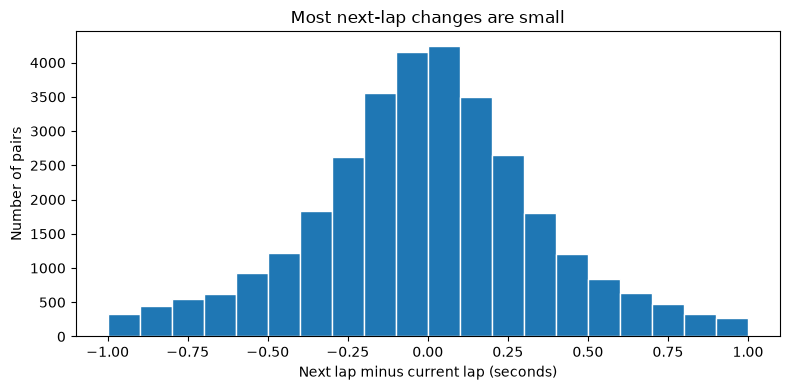

Outside the plotted range: 3,666 pairs. All pairs are included in MAE.


In [3]:
clean["Change"] = clean["NextLapTimeSeconds"] - clean["LapTimeSeconds"]
clean["BaselineError"] = clean["Change"].abs()

print(f"Baseline MAE: {clean['BaselineError'].mean():.3f} seconds")
print(f"Median absolute change: {clean['BaselineError'].median():.3f} seconds")
print(f"Within 1 second: {clean['BaselineError'].le(1).mean():.1%}")

clean["Change"].plot.hist(bins=20, range=(-1, 1), figsize=(8, 4), edgecolor="white")
plt.xlabel("Next lap minus current lap (seconds)")
plt.ylabel("Number of pairs")
plt.title("Most next-lap changes are small")
plt.tight_layout()
plt.show()
print(f"Outside the plotted range: {clean['BaselineError'].gt(1).sum():,} pairs. All pairs are included in MAE.")

The histogram shoows that consecutive laps are usually close, with the median value of change being 0.243 seconds. Using a same-lap baseline is really strong and the main objective is to demonstrate improvement on validation data.
Drop outliers

## 3. Are some races harder to predict?

MAE  Median absolute error
Season EventName                                              
2022   Monaco Grand Prix       1.533274                 0.5250
       British Grand Prix      1.258065                 0.2300
2023   Mexico City Grand Prix  0.971823                 0.2325
       Monaco Grand Prix       0.902496                 0.3540
2022   Singapore Grand Prix    0.802889                 0.4390
2023   São Paulo Grand Prix    0.705699                 0.1885
       Dutch Grand Prix        0.703779                 0.2965
2022   Japanese Grand Prix     0.657396                 0.4530

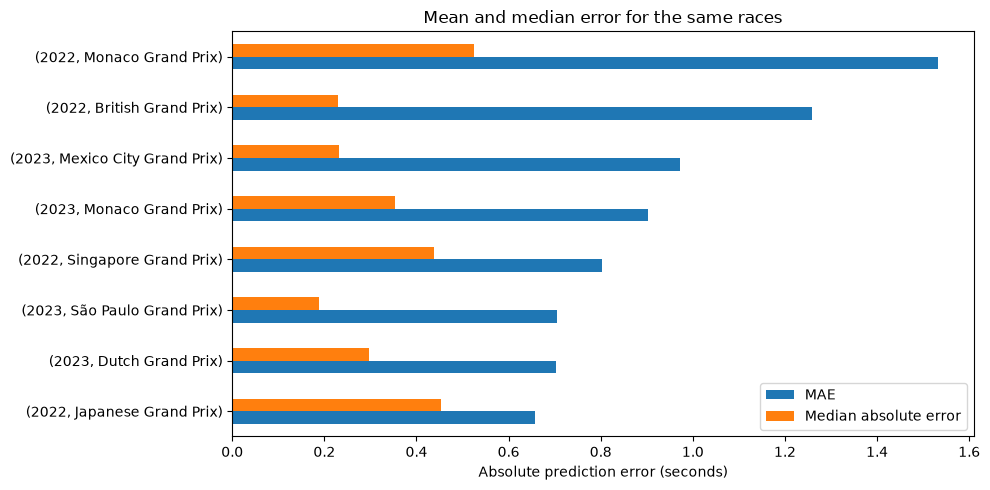

In [18]:
grouped_errors = clean.groupby(
    ["Season", "EventName"]
)["BaselineError"]

race_errors = pd.DataFrame({
    "MAE": grouped_errors.mean(),
    "Median absolute error": grouped_errors.median()
})

top_races = race_errors.nlargest(8, "MAE")

display(top_races)

top_races.sort_values("MAE").plot.barh(figsize=(10, 5))
plt.xlabel("Absolute prediction error (seconds)")
plt.ylabel("")
plt.title("Mean and median error for the same races")
plt.tight_layout()
plt.show()

Mean absolute error exceeds median absolute error in all eight selected races, indicating that larger errors increase the averages. In Britain and São Paulo, typical errors are relatively small despite high MAE. I will therefore compare models using both typical and large-error performance, inspect the difficult cases, and check results by race.

The Monaco grand prix has a bigger MAE due to rain during the race making times slower than usual, followed by certain drier times.

## 4. Does using more past laps help?

Build history from usable laps, then select eligible pairs. Start again after a gap.
Every prediction uses only the current lap and earlier laps.

In [25]:
usable = (
    training["LapTimeSeconds"].notna()
    & training["IsPitLap"].eq(False)
    & training["TrackStatus"].eq("1")
    & training["IsAccurate"].eq(True)
)
keys = ["Season", "RoundNumber", "DriverNumber"]
history = training[usable].sort_values(keys + ["LapNumber"]).copy()
history["Segment"] = history.groupby(keys)["LapNumber"].diff().ne(1).cumsum()
groups = history.groupby("Segment")
history["HistoryLaps"] = groups.cumcount() + 1

In [26]:
history["Mean3"] = groups["LapTimeSeconds"].transform(
    lambda times: times.rolling(3).mean()
)
history["Smoothing"] = groups["LapTimeSeconds"].transform(
    lambda times: times.ewm(alpha=0.9, adjust=False).mean()
)
pairs = history[history["EligiblePair"]].copy()
comparison = pairs.dropna(subset=["Mean3"]).copy()

errors = pd.DataFrame({
    "Last lap": comparison["NextLapTimeSeconds"] - comparison["LapTimeSeconds"],
    "Three-lap average": comparison["NextLapTimeSeconds"] - comparison["Mean3"],
    "Smoothing": comparison["NextLapTimeSeconds"] - comparison["Smoothing"]
})
display(pd.DataFrame({
    "MAE (seconds)": errors.abs().mean(),
    "RMSE (seconds)": np.sqrt(errors.pow(2).mean())
}).round(3))
print(f"All three methods use the same {len(comparison):,} pairs with at least 3 history laps.")

,MAE (seconds),RMSE (seconds)
Last lap,0.389,0.710
Three-lap average,0.449,1.004
Smoothing,0.384,0.703


All three methods use the same 29,816 pairs with at least 3 history laps.


In [27]:
pairs["Error"] = (pairs["NextLapTimeSeconds"] - pairs["LapTimeSeconds"]).abs()
pairs["HistoryGroup"] = np.where(pairs["HistoryLaps"].eq(1), "First usable lap", "More history")
display(pairs.groupby("HistoryGroup").agg(
    Pairs=("Error", "size"),
    BaselineMAE=("Error", "mean")
).round(3))

display(pairs.nlargest(5, "Error")[[
    "Season", "EventName", "Driver", "LapNumber", "Error", "HistoryLaps"
]])

,Pairs,BaselineMAE
HistoryGroup,,
First usable lap,3152,1.374
More history,32721,0.404


,Season,EventName,Driver,LapNumber,Error,HistoryLaps
44750,2023,Mexico City Grand Prix,PIA,36.0,64.690,1
44608,2023,Mexico City Grand Prix,RUS,36.0,57.704,1
43969,2023,Mexico City Grand Prix,TSU,36.0,57.436,1
44789,2023,São Paulo Grand Prix,VER,4.0,56.925,1
44182,2023,Mexico City Grand Prix,HUL,36.0,54.633,1


## 5. How does pace change as tyres age?

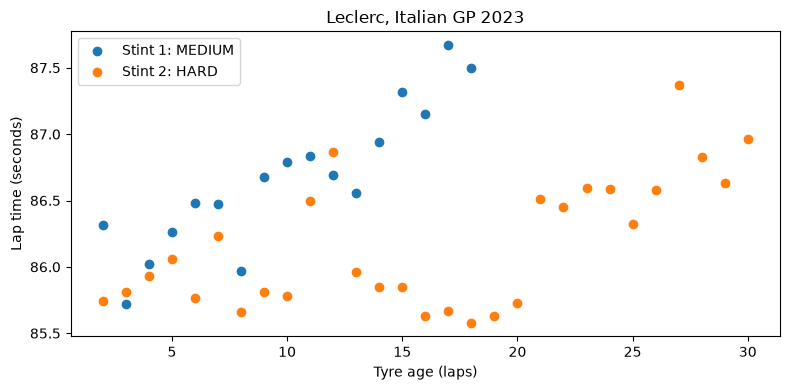

In [28]:
example = clean[
    clean["Season"].eq(2023)
    & clean["EventName"].eq("Italian Grand Prix")
    & clean["Driver"].eq("LEC")
]

fig, ax = plt.subplots(figsize=(8, 4))
for stint, rows in example.groupby("Stint"):
    compound = rows["Compound"].iloc[0]
    ax.scatter(rows["TyreLife"], rows["LapTimeSeconds"], label=f"Stint {int(stint)}: {compound}")
ax.set(xlabel="Tyre age (laps)", ylabel="Lap time (seconds)", title="Leclerc, Italian GP 2023")
ax.legend()
plt.tight_layout()
plt.show()

Tyre age and compound are worth testing as inputs. This plot alone cannot separate
tyre wear from fuel, traffic or other changes during the race.

## What to try next

- Compare smoothing and ARIMA against the last-lap baseline on the same pairs.
- Check short-history errors separately.
- Test whether tyre age and compound improve predictions.
- Use 2024 to validate choices; keep 2025 for the final test.

Next-lap values and `EligiblePair` are for evaluation, never model inputs.